# 13 · NRTL properties, VLE and parameter fitting

This notebook uses **water + ethanol**, the bundled published NRTL coefficients,
and the native SAFT-γ Mie EOS. It calculates liquid activities, excess properties
and ideal-vapour VLE, then fits a small NRTL model to actual SAFT predictions.
The fit is **model reduction**, not a fit to experimental measurements.

Requirements: the standard ThermoWeave Conda environment, or
`python -m pip install -e ".[nrtl,tutorials]"` from the repository root. JAX is
required; Julia, RDKit and external COSMO files are not. Run all cells in order.
Keep this notebook in `tutorials/`, beside `data/real_mixtures.json`.

NRTL follows [Renon & Prausnitz (1968)](https://doi.org/10.1002/aic.690140124).
The directed coefficients and convention match the
[pinned Clapeyron collection](https://github.com/ClapeyronThermo/Clapeyron.jl/blob/cb620c1af72b7bcea8407e4f970dbae64a7f8c9d/database/Activity/NRTL/NRTL_unlike.csv):
$\tau_{ij}=a_{ij}+b_{ij}/T$, $G_{ij}=\exp(-\alpha_{ij}\tau_{ij})$.
a and alpha are dimensionless; b is in K. a/b matrices are directed, in the
specified component order. These are fitted mixture parameters; SMILES do not
supply NRTL coefficients.

<a class="md-button" href="13_nrtl_and_parameter_fitting.ipynb" download>Download notebook</a>


In [1]:
import json
import tempfile
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from thermoweave import NRTL, SAFTgammaMie
from thermoweave.nrtl import NRTLFitProblem
from thermoweave.equilibrium.vle import bubble_pressure

names = ["water", "ethanol"]
model = NRTL.from_database(names)
print("Component order:", model.component_names)
print("a =\n", model.a)
print("b [K] =\n", model.b)
print("alpha =\n", model.alpha)
print("Parameter source:", model.reference)

Component order: ('water', 'ethanol')
a =
 [[ 0.     3.458]
 [-0.801  0.   ]]
b [K] =
 [[   0.  -586.1]
 [ 246.2    0. ]]
alpha =
 [[0.  0.3]
 [0.3 0. ]]
Parameter source: https://github.com/ClapeyronThermo/Clapeyron.jl/blob/cb620c1af72b7bcea8407e4f970dbae64a7f8c9d/database/Activity/NRTL/NRTL_unlike.csv


## Activities and excess properties

`ln_activity_coefficients` returns natural logarithms. Activities are
$x_i\gamma_i$; `reduced_excess_gibbs` returns $g^E/(RT)$.
$H^E$ and $C_p^E$ follow exact temperature derivatives of the same Gibbs function.
NRTL supplies liquid nonideality; it has no volume or pressure EOS.

The batch path evaluates a composition grid with a compiled, vectorized JAX
kernel. It also accepts one temperature per row. Public calls manage float64
locally without changing your global JAX precision setting.

ln gamma: [0.4778084 0.1371735]
activities: [0.6450146  0.68821629]
gE/(RT): 0.27342746027709053


HE [J/mol]: -110.99276939803335


CpE [J/(mol K)]: 2.5323223788072715


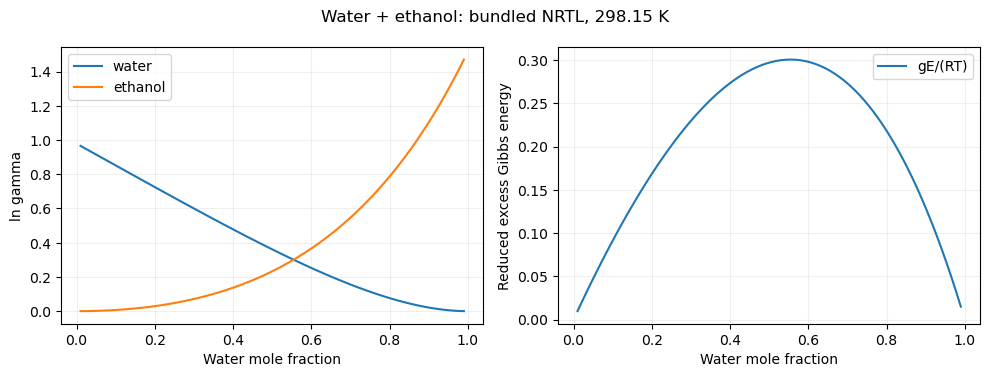

In [2]:
T = 298.15
x = np.array([0.4, 0.6])
print("ln gamma:", model.ln_activity_coefficients(T, x))
print("activities:", model.activities(T, x))
print("gE/(RT):", model.reduced_excess_gibbs(T, x))
print("HE [J/mol]:", model.excess_enthalpy(T, x))
print("CpE [J/(mol K)]:", model.excess_heat_capacity(T, x))
J = model.ln_activity_coefficients_jacobian(T, x)
np.testing.assert_allclose(x @ J, 0., atol=1e-13)  # Gibbs–Duhem check

xs = np.linspace(0.01, 0.99, 80)
X = np.column_stack([xs, 1-xs])
lng = model.ln_activity_coefficients_batch(T, X)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for i, name in enumerate(names):
    axes[0].plot(xs, lng[:, i], label=name)
axes[0].set_ylabel("ln gamma")
axes[1].plot(xs, np.sum(X*lng, axis=1), label="gE/(RT)")
axes[1].set_ylabel("Reduced excess Gibbs energy")
for ax in axes:
    ax.set_xlabel("Water mole fraction"); ax.grid(alpha=0.2); ax.legend()
fig.suptitle("Water + ethanol: bundled NRTL, 298.15 K")
fig.tight_layout(); plt.show()

## Bubble pressure and vapour composition

Use NRTL through the existing VLE API. This calculation assumes **ideal vapour**
and neglects the Poynting correction:
$P=\sum_i x_i\gamma_i P_i^{sat}$, $y_i=x_i\gamma_iP_i^{sat}/P$.
Saturation pressures are independent inputs, not NRTL predictions.

The Antoine correlations below are the cited NIST WebBook values already stored
in `data/real_mixtures.json` ([water](https://webbook.nist.gov/cgi/cbook.cgi?ID=C7732185&Type=ANTOINE),
[ethanol](https://webbook.nist.gov/cgi/cbook.cgi?ID=C64175&Type=ANTOINE)).
We check their validity intervals and convert bar to Pa.

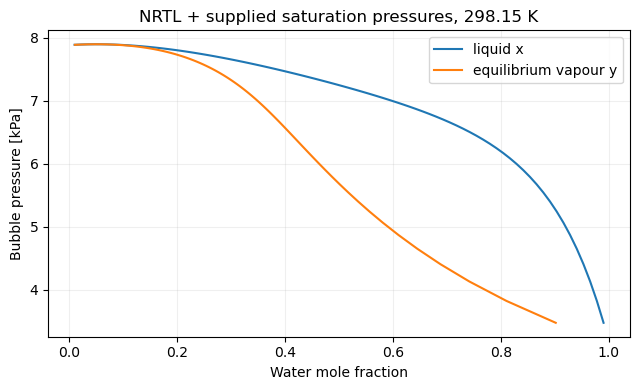

In [3]:
properties = json.loads(Path("data/real_mixtures.json").read_text())["components"]
psat = []
for name in names:
    p = properties[name]["antoine_bar"]
    assert p["T_min_K"] <= T <= p["T_max_K"]
    psat.append(1e5 * 10**(p["A"]-p["B"]/(T+p["C"])))
psat = np.asarray(psat)
results = [bubble_pressure(model, row, T, psat) for row in X]
pressures = np.array([r.pressure_Pa for r in results])
vapours = np.array([r.vapor_composition for r in results])
np.testing.assert_allclose(vapours*pressures[:, None], X*np.exp(lng)*psat,
                           rtol=1e-12)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(xs, pressures/1000, label="liquid x")
ax.plot(vapours[:, 0], pressures/1000, label="equilibrium vapour y")
ax.set(xlabel="Water mole fraction", ylabel="Bubble pressure [kPa]",
       title="NRTL + supplied saturation pressures, 298.15 K")
ax.grid(alpha=0.2); ax.legend(); fig.tight_layout(); plt.show()

## Fit NRTL to actual SAFT predictions

We evaluate the unchanged bundled SAFT-γ Mie model at three temperatures and nine
compositions. Manual group counts make the chemistry explicit and avoid an
RDKit dependency. The targets are **computed SAFT activities**, not measured
activities and not synthetic regular-solution data.

We fit both directions of a and b, keep alpha=0.3 fixed, and retain a separate
temperature/composition grid for validation. Multiple temperatures are necessary
to distinguish a from b using activity data. At one temperature only a+b/T is
identifiable; the helper rejects that unconstrained fit.

In [4]:
saft = SAFTgammaMie(
    {"water": {"H2O": 1}, "ethanol": {"CH3": 1, "CH2OH": 1}},
    pressure_Pa=101325.,
)
train_xs = np.linspace(0.08, 0.92, 9)
train_X = np.tile(np.column_stack([train_xs, 1-train_xs]), (3, 1))
train_T = np.repeat([288.15, 318.15, 348.15], len(train_xs))
train_lng = saft.ln_activity_coefficients_batch(train_T, train_X)
print("Training rows:", len(train_X), "; observed ln-gamma values:", train_lng.size)
print("Target provenance: actual bundled SAFT-γ Mie, 101325 Pa")

problem = NRTLFitProblem(model)
for field, bounds in [("a", (-10., 10.)), ("b", (-4000., 4000.))]:
    for i, j in [(0, 1), (1, 0)]:
        problem.vary(field, i, j, bounds=bounds)
problem.add_ln_gamma(train_T, train_X, train_lng,
                     label="SAFT predictions; model-to-model reduction")
result = problem.fit(max_nfev=400)
print(result.report())
assert result.success and result.rank == 4
assert result.cost < result.initial_cost
fitted = result.model

Training rows: 27 ; observed ln-gamma values: 54
Target provenance: actual bundled SAFT-γ Mie, 101325 Pa


NRTL fit (tau=a+b/T+tau_log*ln(T/K)+tau_linear*T; alpha(T)=alpha+alpha_linear*T)
`ftol` termination condition is satisfied.; initial quadratic cost 0.0556048; final objective 0.00120007
Jacobian rank 4/4; condition 3.238e+04
parameter                         fitted       local std. error
a[water,ethanol]                    1.53683           0.167227
a[ethanol,water]                   0.237919          0.0982789
b[water,ethanol]                   -8.19388            52.8476
b[ethanol,water]                   -98.2199            31.0279
SAFT predictions; model-to-model reduction: 54 residuals; normalized RMS 0.00666687


The optimizer uses exact JAX parameter Jacobians and bounded SciPy least
squares. The report shows residual RMS, Jacobian rank, condition number and
local standard errors. A high condition number warns of parameter correlation;
small residuals do not make individual coefficients well determined. These local
standard errors describe this deterministic regression, not experimental
uncertainty or physical parameter confidence.

The original published water/ethanol model remains `model`; `result.model` is the
separately fitted representation of SAFT. Keep that provenance when saving it.

Held-out ln-gamma RMS: 0.007320554989031593


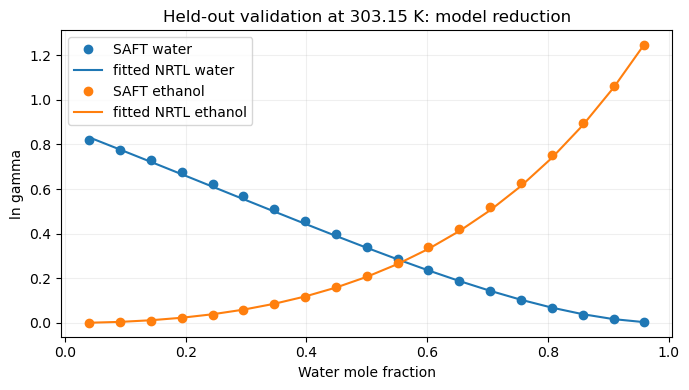

JSON round trip verified; schema: thermoweave.nrtl.v2


In [5]:
validation_T = 303.15  # absent from the training temperatures
validation_xs = np.linspace(0.04, 0.96, 19)
validation_X = np.column_stack([validation_xs, 1-validation_xs])
reference = saft.ln_activity_coefficients_batch(validation_T, validation_X)
predicted = fitted.ln_activity_coefficients_batch(validation_T, validation_X)
rms = np.sqrt(np.mean((predicted-reference)**2))
print("Held-out ln-gamma RMS:", rms)
assert np.all(np.isfinite(predicted)) and rms < 0.03
fig, ax = plt.subplots(figsize=(7, 4))
for i, name in enumerate(names):
    color = f"C{i}"
    ax.plot(validation_xs, reference[:, i], "o", color=color, label=f"SAFT {name}")
    ax.plot(validation_xs, predicted[:, i], "-", color=color, label=f"fitted NRTL {name}")
ax.set(xlabel="Water mole fraction", ylabel="ln gamma",
       title="Held-out validation at 303.15 K: model reduction")
ax.grid(alpha=0.2); ax.legend(); fig.tight_layout(); plt.show()

with tempfile.TemporaryDirectory() as folder:
    path = Path(folder)/"nrtl-fit.json"
    result.save(path)  # use a permanent project path to retain your own fit
    loaded = NRTL.from_json(path)
    np.testing.assert_allclose(loaded.ln_activity_coefficients_batch(validation_T, validation_X),
                               predicted)
    print("JSON round trip verified; schema:", loaded.to_dict()["schema"])

## Multicomponent models and other measurements

The same implementation supports a ternary mixture when all directed pair
parameters are available. Combining binary fits is an assumption to validate.
This particular water/ethanol/methanol example demonstrates ternary activities;
it is not an SLLE parameter set.

In [6]:
ternary = NRTL.from_database(["water", "ethanol", "methanol"])
print("Ternary component order:", ternary.components)
print("Ternary ln gamma:", ternary.ln_activity_coefficients(298.15, [0.2, 0.4, 0.4]))

Ternary component order: ('water', 'ethanol', 'methanol')


Ternary ln gamma: [ 0.53671642  0.07026565 -0.04589724]


For experimental fitting, replace the SAFT targets with measurements, keep
units and component order explicit, and validate against independent data.
`NRTLFitProblem` also supplies `add_activity_coefficients`, `add_vle`,
`add_bubble_pressure`, `add_excess_enthalpy` and `add_lle`. Missing ln-gamma entries
can be NaN; `component=` supports measurements of one species. Relative
inverse-variance weights apply to the documented normalized residual scales.
See the [complete fitting guide](../advanced/nrtl-fitting.md).

Liquid tie-line equality alone does not prove stability. NRTL can be passed to
the same SLE/ReducedHELD interfaces used in notebooks 07 and 10–12, with an
appropriate NRTL parameter set and separate solid fusion/Gibbs inputs. Validate
stability and material balances after fitting LLE or using a model for SLLE.
Do not assume this water/ethanol fit predicts other components or temperatures
outside its fitted range.